<a href="https://colab.research.google.com/github/ShahariarMdHossen/ShahariarMdHossen/blob/main/DC_G_07_MBA_BF_xlsx.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display

# Upload our updated TP Excel workbook
uploaded = files.upload()

# Get uploaded filename
file_name = next(iter(uploaded))

# Read the Final_VAR_Data sheet
df = pd.read_excel(file_name, sheet_name="Final_VAR_Data")

# Convert Date column to datetime
df["Date"] = pd.to_datetime(df["Date"])

# Select our four research variables
variables = [
    "Inflation_YoY_pct",
    "M2_Growth_YoY_pct",
    "Repo_Rate_pct",
    "Brent_Oil_Growth_YoY_pct"
]

# Create analysis dataset
data = df[["Date"] + variables].copy()
data = data.sort_values("Date").reset_index(drop=True)

print("Excel file loaded successfully!")
print("Dataset shape:", data.shape)
display(data.head())

Saving DC G#07 MBA BF.xlsx to DC G#07 MBA BF.xlsx
Excel file loaded successfully!
Dataset shape: (125, 5)


,Date,Inflation_YoY_pct,M2_Growth_YoY_pct,Repo_Rate_pct,Brent_Oil_Growth_YoY_pct
0,2016-01-01,6.067961,14.958762,6.75,-35.966736
1,2016-02-01,5.618297,15.059600,6.75,-42.659758
2,2016-03-01,5.650466,15.476541,6.75,-29.928315
3,2016-04-01,5.607300,16.197987,6.75,-28.787879
4,2016-05-01,5.450975,16.177417,6.75,-27.089783


In [2]:
# Check dataset information
print("DATA INFORMATION")
print("-" * 40)
data.info()

# Check date range
print("\nDATE RANGE")
print("Start:", data["Date"].min())
print("End:", data["Date"].max())

# Check missing values
print("\nMISSING VALUES")
display(data.isnull().sum().to_frame("Missing Values"))

# Check duplicate dates
print("\nDUPLICATE DATES")
print(data["Date"].duplicated().sum())

# Check observations
print("\nTOTAL OBSERVATIONS:", len(data))

DATA INFORMATION
----------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 125 entries, 0 to 124
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Date                      125 non-null    datetime64[ns]
 1   Inflation_YoY_pct         125 non-null    float64       
 2   M2_Growth_YoY_pct         125 non-null    float64       
 3   Repo_Rate_pct             125 non-null    float64       
 4   Brent_Oil_Growth_YoY_pct  125 non-null    float64       
dtypes: datetime64[ns](1), float64(4)
memory usage: 5.0 KB

DATE RANGE
Start: 2016-01-01 00:00:00
End: 2026-05-01 00:00:00

MISSING VALUES


,Missing Values
Date,0
Inflation_YoY_pct,0
M2_Growth_YoY_pct,0
Repo_Rate_pct,0
Brent_Oil_Growth_YoY_pct,0



DUPLICATE DATES
0

TOTAL OBSERVATIONS: 125


In [3]:
# Descriptive statistics
desc = data[variables].describe().T

desc["Median"] = data[variables].median()
desc["Skewness"] = data[variables].skew()
desc["Kurtosis"] = data[variables].kurtosis()

# Arrange columns
desc = desc[
    ["count", "mean", "Median", "std",
     "min", "max", "Skewness", "Kurtosis"]
]

desc = desc.round(4)

print("DESCRIPTIVE STATISTICS")
display(desc)

DESCRIPTIVE STATISTICS


,count,mean,Median,std,min,max,Skewness,Kurtosis
Inflation_YoY_pct,125.0,7.1148,5.9436,1.9731,5.0225,11.6662,0.6940,-1.1432
M2_Growth_YoY_pct,125.0,10.7509,11.1957,3.3106,5.8950,18.2672,0.2108,-1.0320
Repo_Rate_pct,125.0,6.7600,6.0000,1.7170,4.7500,10.0000,0.8406,-0.4139
Brent_Oil_Growth_YoY_pct,125.0,10.2510,-1.2469,39.9464,-67.2753,178.1116,1.1420,1.8217


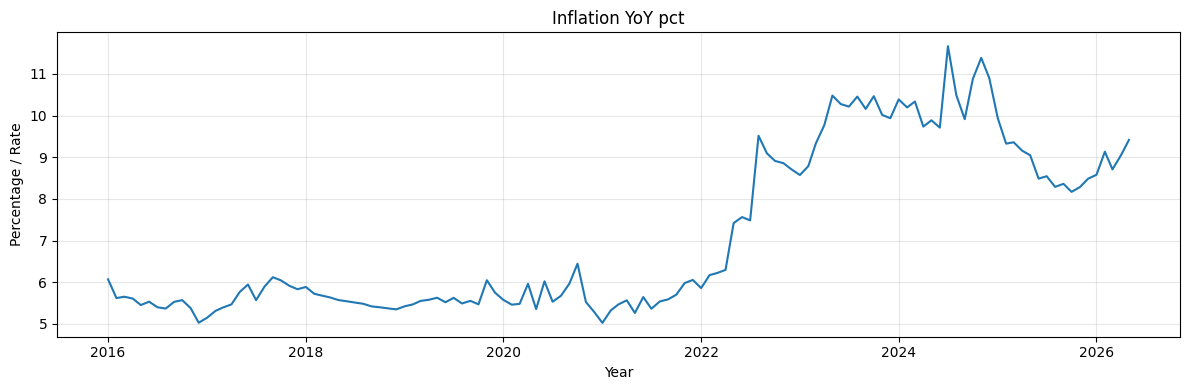

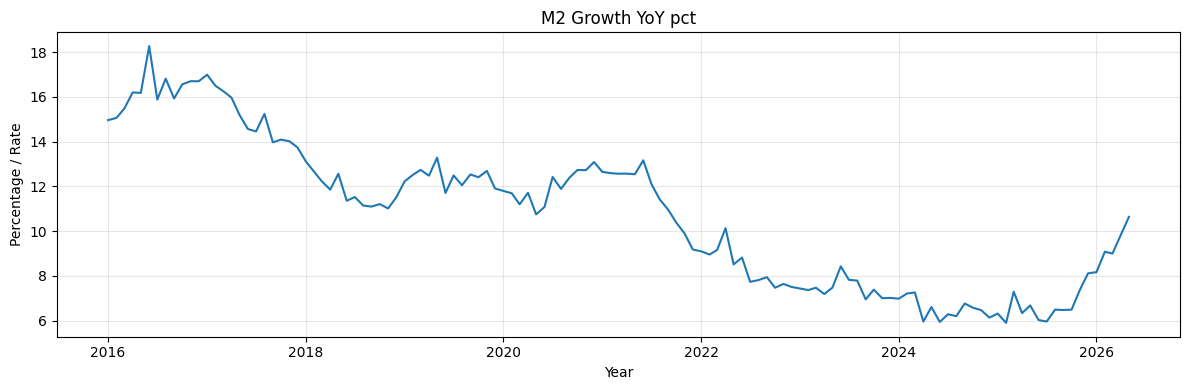

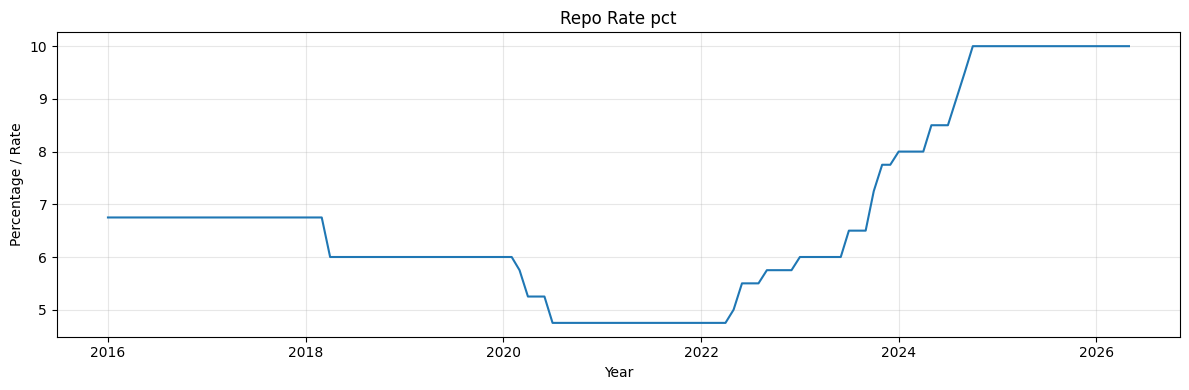

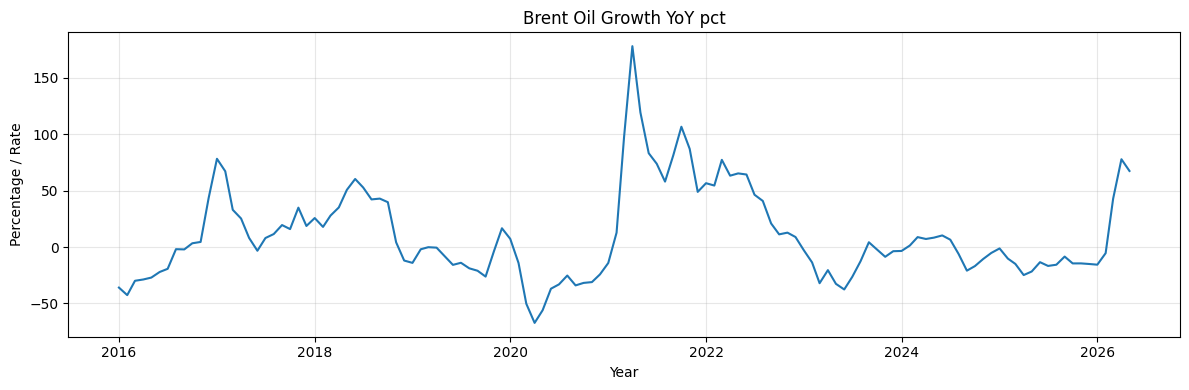

In [4]:
for col in variables:
    plt.figure(figsize=(12, 4))

    plt.plot(data["Date"], data[col])

    plt.title(col.replace("_", " "))
    plt.xlabel("Year")
    plt.ylabel("Percentage / Rate")
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

CORRELATION MATRIX


,Inflation_YoY_pct,M2_Growth_YoY_pct,Repo_Rate_pct,Brent_Oil_Growth_YoY_pct
Inflation_YoY_pct,1.0000,-0.8303,0.6217,-0.2193
M2_Growth_YoY_pct,-0.8303,1.0000,-0.4437,0.1025
Repo_Rate_pct,0.6217,-0.4437,1.0000,-0.2671
Brent_Oil_Growth_YoY_pct,-0.2193,0.1025,-0.2671,1.0000


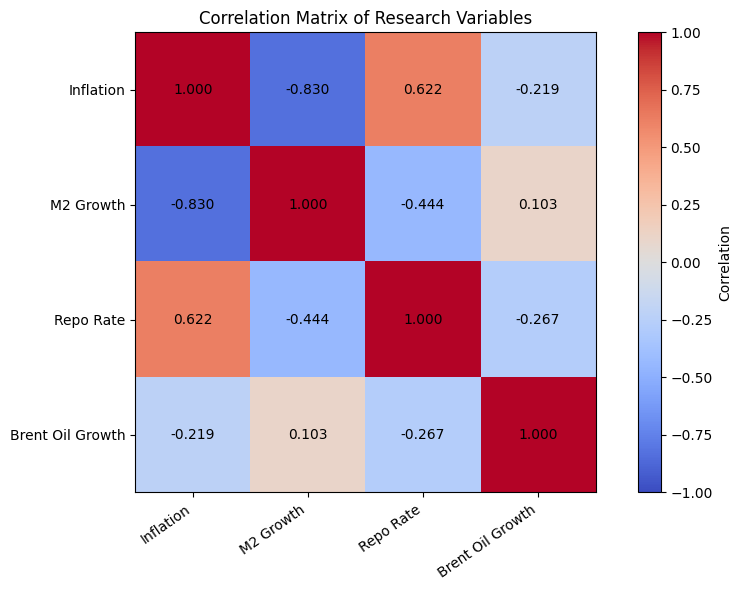

In [5]:
# STEP 1E: CORRELATION MATRIX

# Calculate correlation
corr = data[variables].corr()

print("CORRELATION MATRIX")
display(corr.round(4))

# Draw heatmap
plt.figure(figsize=(9, 6))

plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlation")

labels = [
    "Inflation",
    "M2 Growth",
    "Repo Rate",
    "Brent Oil Growth"
]

plt.xticks(range(4), labels, rotation=35, ha="right")
plt.yticks(range(4), labels)

for i in range(4):
    for j in range(4):
        plt.text(
            j, i,
            f"{corr.iloc[i, j]:.3f}",
            ha="center",
            va="center"
        )

plt.title("Correlation Matrix of Research Variables")
plt.tight_layout()
plt.show()

In [6]:
# STEP 2A: INSTALL REQUIRED LIBRARY

!pip -q install statsmodels arch

In [7]:
# AUGMENTED DICKEY-FULLER TEST

from statsmodels.tsa.stattools import adfuller

print("ADF UNIT ROOT TEST")
print("=" * 65)

for col in variables:

    result = adfuller(data[col], autolag="AIC")

    print("\nVariable:", col)
    print("ADF Statistic:", round(result[0], 4))
    print("p-value:", round(result[1], 4))
    print("Lags Used:", result[2])
    print("Observations:", result[3])

    if result[1] < 0.05:
        print("Decision: Stationary (Reject H0)")
    else:
        print("Decision: Non-Stationary (Fail to Reject H0)")

ADF UNIT ROOT TEST

Variable: Inflation_YoY_pct
ADF Statistic: -0.7995
p-value: 0.8193
Lags Used: 1
Observations: 123
Decision: Non-Stationary (Fail to Reject H0)

Variable: M2_Growth_YoY_pct
ADF Statistic: -1.8103
p-value: 0.3753
Lags Used: 3
Observations: 121
Decision: Non-Stationary (Fail to Reject H0)

Variable: Repo_Rate_pct
ADF Statistic: -0.1768
p-value: 0.9412
Lags Used: 3
Observations: 121
Decision: Non-Stationary (Fail to Reject H0)

Variable: Brent_Oil_Growth_YoY_pct
ADF Statistic: -2.4083
p-value: 0.1394
Lags Used: 13
Observations: 111
Decision: Non-Stationary (Fail to Reject H0)


/tmp/ipykernel_7329/1173396485.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(data[col], autolag="AIC")
/tmp/ipykernel_7329/1173396485.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(data[col], autolag="AIC")
/tmp/ipykernel_7329/1173396485.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on 

In [8]:
# STEP 2B: FIRST DIFFERENCE ADF TEST

from statsmodels.tsa.stattools import adfuller
import pandas as pd

# Create first difference data
diff_data = data[variables].diff().dropna()

print("ADF TEST ON FIRST DIFFERENCE")
print("=" * 65)

adf_diff_results = []

for col in variables:

    result = adfuller(diff_data[col], autolag="AIC")

    p_value = result[1]

    decision = (
        "Stationary"
        if p_value < 0.05
        else "Non-Stationary"
    )

    adf_diff_results.append({
        "Variable": col,
        "ADF Statistic": result[0],
        "p-value": p_value,
        "Lags": result[2],
        "Observations": result[3],
        "Decision": decision
    })

adf_diff_table = pd.DataFrame(adf_diff_results)

display(adf_diff_table.round(4))

ADF TEST ON FIRST DIFFERENCE


/tmp/ipykernel_7329/992235304.py:16: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(diff_data[col], autolag="AIC")
/tmp/ipykernel_7329/992235304.py:16: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(diff_data[col], autolag="AIC")
/tmp/ipykernel_7329/992235304.py:16: FutureWarning: adfuller currently returns a plain tuple whose length depe

,Variable,ADF Statistic,p-value,Lags,Observations,Decision
0,Inflation_YoY_pct,-13.1842,0.0000,0,123,Stationary
1,M2_Growth_YoY_pct,-5.0374,0.0000,2,121,Stationary
2,Repo_Rate_pct,-4.0358,0.0012,2,121,Stationary
3,Brent_Oil_Growth_YoY_pct,-4.7854,0.0001,11,112,Stationary


In [9]:
!pip -q install arch

In [10]:
# STEP 2C: PHILLIPS-PERRON TEST

from arch.unitroot import PhillipsPerron
import pandas as pd

pp_results = []

for stage, series in [
    ("Level", data[variables]),
    ("First Difference", diff_data)
]:
    for col in variables:

        test = PhillipsPerron(series[col], trend="c")

        pp_results.append({
            "Stage": stage,
            "Variable": col,
            "PP Statistic": test.stat,
            "p-value": test.pvalue,
            "Decision": (
                "Stationary" if test.pvalue < 0.05
                else "Non-Stationary"
            )
        })

pp_table = pd.DataFrame(pp_results)

display(pp_table.round(4))

,Stage,Variable,PP Statistic,p-value,Decision
0,Level,Inflation_YoY_pct,-0.8851,0.7928,Non-Stationary
1,Level,M2_Growth_YoY_pct,-1.4566,0.5549,Non-Stationary
2,Level,Repo_Rate_pct,-0.0040,0.9582,Non-Stationary
3,Level,Brent_Oil_Growth_YoY_pct,-2.7345,0.0683,Non-Stationary
4,First Difference,Inflation_YoY_pct,-13.1171,0.0000,Stationary
5,First Difference,M2_Growth_YoY_pct,-15.1040,0.0000,Stationary
6,First Difference,Repo_Rate_pct,-9.2629,0.0000,Stationary
7,First Difference,Brent_Oil_Growth_YoY_pct,-7.3634,0.0000,Stationary


In [11]:
# STEP 2D: KPSS TEST

from statsmodels.tsa.stattools import kpss
import pandas as pd

kpss_results = []

for stage, series in [
    ("Level", data[variables]),
    ("First Difference", diff_data)
]:
    for col in variables:

        statistic, pvalue, lags, critical = kpss(
            series[col],
            regression="c",
            nlags="auto"
        )

        kpss_results.append({
            "Stage": stage,
            "Variable": col,
            "KPSS Statistic": statistic,
            "p-value": pvalue,
            "Lags": lags,
            "Decision": (
                "Stationary" if pvalue >= 0.05
                else "Non-Stationary"
            )
        })

kpss_table = pd.DataFrame(kpss_results)

display(kpss_table.round(4))

/tmp/ipykernel_7329/1412509036.py:14: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  statistic, pvalue, lags, critical = kpss(
/tmp/ipykernel_7329/1412509036.py:14: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  statistic, pvalue, lags, critical = kpss(
/tmp/ipykernel_7329/1412509036.py:14: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  statistic, pvalue, lags, critical = kpss(
/tmp/ipykernel_7329/141250

,Stage,Variable,KPSS Statistic,p-value,Lags,Decision
0,Level,Inflation_YoY_pct,1.4107,0.01,6,Non-Stationary
1,Level,M2_Growth_YoY_pct,1.6151,0.01,6,Non-Stationary
2,Level,Repo_Rate_pct,0.8246,0.01,6,Non-Stationary
3,Level,Brent_Oil_Growth_YoY_pct,0.0948,0.10,6,Stationary
4,First Difference,Inflation_YoY_pct,0.1280,0.10,6,Stationary
5,First Difference,M2_Growth_YoY_pct,0.2321,0.10,4,Stationary
6,First Difference,Repo_Rate_pct,0.7875,0.01,3,Non-Stationary
7,First Difference,Brent_Oil_Growth_YoY_pct,0.0611,0.10,0,Stationary


In [12]:
# ROBUSTNESS CHECK: ADF AND KPSS
from statsmodels.tsa.stattools import adfuller, kpss
import pandas as pd

robust_results = []

for stage, series in [
    ("Level", data[variables]),
    ("First Difference", diff_data)
]:

    for col in variables:

        for regression in ["c", "ct"]:

            # ADF
            adf_result = adfuller(
                series[col],
                regression=regression,
                autolag="AIC"
            )

            # KPSS
            kpss_stat, kpss_p, _, _ = kpss(
                series[col],
                regression=regression,
                nlags="auto"
            )

            robust_results.append({
                "Stage": stage,
                "Variable": col,
                "Specification": regression,
                "ADF p-value": adf_result[1],
                "KPSS p-value": kpss_p
            })

robust_table = pd.DataFrame(robust_results)

display(robust_table.round(4))

/tmp/ipykernel_7329/564575926.py:17: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(
/tmp/ipykernel_7329/564575926.py:24: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_stat, kpss_p, _, _ = kpss(
/tmp/ipykernel_7329/564575926.py:24: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to s

,Stage,Variable,Specification,ADF p-value,KPSS p-value
0,Level,Inflation_YoY_pct,c,0.8193,0.0100
1,Level,Inflation_YoY_pct,ct,0.6630,0.0100
2,Level,M2_Growth_YoY_pct,c,0.3753,0.0100
3,Level,M2_Growth_YoY_pct,ct,0.9561,0.1000
4,Level,Repo_Rate_pct,c,0.9412,0.0100
5,Level,Repo_Rate_pct,ct,0.9250,0.0100
6,Level,Brent_Oil_Growth_YoY_pct,c,0.1394,0.1000
7,Level,Brent_Oil_Growth_YoY_pct,ct,0.4050,0.1000
8,First Difference,Inflation_YoY_pct,c,0.0000,0.1000
9,First Difference,Inflation_YoY_pct,ct,0.0000,0.1000


In [14]:
# STEP 2E: ZIVOT-ANDREWS STRUCTURAL BREAK TEST
from statsmodels.tsa.stattools import zivot_andrews
import pandas as pd

za_results = []

for col in variables:

    result = zivot_andrews(
        data[col].dropna(),
        maxlag=12,
        regression="ct",
        autolag="AIC"
    )

    za_results.append({
        "Variable": col,
        "ZA Statistic": result[0],
        "p-value": result[1],
        "Critical Value 1%": result[4]["1%"],
        "Critical Value 5%": result[4]["5%"],
        "Critical Value 10%": result[4]["10%"],
        "Break Index": result[3]
    })

za_table = pd.DataFrame(za_results)

print("ZIVOT-ANDREWS STRUCTURAL BREAK TEST")
display(za_table.round(4))

IndexError: invalid index to scalar variable.

In [16]:
# STEP 2E: ZIVOT-ANDREWS STRUCTURAL BREAK TEST
from statsmodels.tsa.stattools import zivot_andrews
import pandas as pd

za_results = []

for col in variables:

    result = zivot_andrews(
        data[col].dropna(),
        maxlag=12,
        regression="ct",
        autolag="AIC"
    )

    za_results.append({
        "Variable": col,
        "ZA Statistic": result[0],
        "p-value": result[1],
        "Critical Value 1%": result[4]["1%"],
        "Critical Value 5%": result[4]["5%"],
        "Critical Value 10%": result[4]["10%"],
        "Break Index": result[3]
    })

za_table = pd.DataFrame(za_results)

print("ZIVOT-ANDREWS STRUCTURAL BREAK TEST")
display(za_table.round(4))

IndexError: invalid index to scalar variable.

In [17]:
result = zivot_andrews(
    data[variables[0]].dropna(),
    maxlag=12,
    regression="ct",
    autolag="AIC"
)

print("Output length:", len(result))
print("Complete output:", result)
print("Critical values:", result[4])

Output length: 5
Complete output: (np.float64(-4.630405757917971), np.float64(0.16056533407164145), {'1%': np.float64(-5.57556), '5%': np.float64(-5.07332), '10%': np.float64(-4.82668)}, 1, np.int64(75))
Critical values: 75


In [18]:
# STEP 2E: ZIVOT-ANDREWS STRUCTURAL BREAK TEST

from statsmodels.tsa.stattools import zivot_andrews
import pandas as pd

za_results = []

for col in variables:

    series = data[col].dropna()

    result = zivot_andrews(
        series,
        maxlag=12,
        regression="ct",
        autolag="AIC"
    )

    break_index = int(result[4])

    za_results.append({
        "Variable": col,
        "ZA Statistic": result[0],
        "p-value": result[1],
        "Critical Value 1%": result[2]["1%"],
        "Critical Value 5%": result[2]["5%"],
        "Critical Value 10%": result[2]["10%"],
        "Lag": result[3],
        "Break Date": series.index[break_index]
    })

za_table = pd.DataFrame(za_results)

print("ZIVOT-ANDREWS STRUCTURAL BREAK TEST")
display(za_table.round(4))

ZIVOT-ANDREWS STRUCTURAL BREAK TEST


,Variable,ZA Statistic,p-value,Critical Value 1%,Critical Value 5%,Critical Value 10%,Lag,Break Date
0,Inflation_YoY_pct,-4.6304,0.1606,-5.5756,-5.0733,-4.8267,1,75
1,M2_Growth_YoY_pct,-2.5652,0.9931,-5.5756,-5.0733,-4.8267,3,106
2,Repo_Rate_pct,-3.9613,0.5299,-5.5756,-5.0733,-4.8267,3,49
3,Brent_Oil_Growth_YoY_pct,-4.1795,0.3866,-5.5756,-5.0733,-4.8267,2,60


In [19]:
# CHECK EXTREME BRENT GROWTH OBSERVATIONS

brent_check = data[
    ["Date", "Brent_Oil_Growth_YoY_pct"]
].copy()

brent_check = brent_check.sort_values(
    "Brent_Oil_Growth_YoY_pct"
)

print("LOWEST 10 BRENT GROWTH OBSERVATIONS")
display(brent_check.head(10))

print("HIGHEST 10 BRENT GROWTH OBSERVATIONS")
display(brent_check.tail(10))

LOWEST 10 BRENT GROWTH OBSERVATIONS


,Date,Brent_Oil_Growth_YoY_pct
51,2020-04-01,-67.275281
52,2020-05-01,-56.028369
50,2020-03-01,-50.301205
1,2016-02-01,-42.659758
89,2023-06-01,-37.635304
53,2020-06-01,-36.966825
0,2016-01-01,-35.966736
56,2020-09-01,-34.028892
54,2020-07-01,-33.125000
88,2023-05-01,-32.651246


HIGHEST 10 BRENT GROWTH OBSERVATIONS


,Date,Brent_Oil_Growth_YoY_pct
74,2022-03-01,77.300613
123,2026-04-01,77.843427
12,2017-01-01,78.246753
68,2021-09-01,81.508516
65,2021-06-01,83.208020
70,2021-11-01,87.037037
62,2021-03-01,97.575758
69,2021-10-01,106.666667
64,2021-05-01,119.354839
63,2021-04-01,178.111588


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [20]:
# INSPECT BRENT CLEAN SHEET

brent_raw = pd.read_excel(
    file_name,
    sheet_name="Brent_Oil_Clean"
)

print("BRENT SHEET COLUMNS:")
print(brent_raw.columns.tolist())

print("\nFIRST 5 ROWS:")
display(brent_raw.head())

print("\nLAST 15 ROWS:")
display(brent_raw.tail(15))

BRENT SHEET COLUMNS:
['Date', 'Brent_Oil_Price_USD_per_bbl', 'Brent_Oil_Growth_YoY_pct', 'Source']

FIRST 5 ROWS:


,Date,Brent_Oil_Price_USD_per_bbl,Brent_Oil_Growth_YoY_pct,Source
0,2015-01-01,48.1,NaN,"World Bank Commodity Price Data (Pink Sheet), ..."
1,2015-02-01,57.9,NaN,"World Bank Commodity Price Data (Pink Sheet), ..."
2,2015-03-01,55.8,NaN,"World Bank Commodity Price Data (Pink Sheet), ..."
3,2015-04-01,59.4,NaN,"World Bank Commodity Price Data (Pink Sheet), ..."
4,2015-05-01,64.6,NaN,"World Bank Commodity Price Data (Pink Sheet), ..."



LAST 15 ROWS:


,Date,Brent_Oil_Price_USD_per_bbl,Brent_Oil_Growth_YoY_pct,Source
122,2025-03-01,72.6,-14.988290,"World Bank Commodity Price Data (Pink Sheet), ..."
123,2025-04-01,67.7,-24.861265,"World Bank Commodity Price Data (Pink Sheet), ..."
124,2025-05-01,64.2,-21.707317,"World Bank Commodity Price Data (Pink Sheet), ..."
125,2025-06-01,71.5,-13.438257,"World Bank Commodity Price Data (Pink Sheet), ..."
126,2025-07-01,71.0,-16.764361,"World Bank Commodity Price Data (Pink Sheet), ..."
127,2025-08-01,68.2,-15.698393,"World Bank Commodity Price Data (Pink Sheet), ..."
128,2025-09-01,68.0,-8.479139,"World Bank Commodity Price Data (Pink Sheet), ..."
129,2025-10-01,64.7,-14.531044,"World Bank Commodity Price Data (Pink Sheet), ..."
130,2025-11-01,63.6,-14.516129,"World Bank Commodity Price Data (Pink Sheet), ..."
131,2025-12-01,62.7,-15.040650,"World Bank Commodity Price Data (Pink Sheet), ..."


In [21]:
# VERIFY BRENT YOY GROWTH FROM ORIGINAL PRICE

brent_raw = brent_raw.sort_values("Date").copy()

# Recalculate YoY growth from original price
brent_raw["Calculated_Growth"] = (
    brent_raw["Brent_Oil_Price_USD_per_bbl"]
    .pct_change(periods=12) * 100
)

# Compare original and recalculated growth
brent_raw["Difference"] = (
    brent_raw["Brent_Oil_Growth_YoY_pct"]
    - brent_raw["Calculated_Growth"]
)

print("BRENT GROWTH VERIFICATION")

display(
    brent_raw[
        ["Date",
         "Brent_Oil_Price_USD_per_bbl",
         "Brent_Oil_Growth_YoY_pct",
         "Calculated_Growth",
         "Difference"]
    ].tail(15).round(4)
)

print(
    "Maximum absolute difference:",
    brent_raw["Difference"].abs().max()
)

BRENT GROWTH VERIFICATION


,Date,Brent_Oil_Price_USD_per_bbl,Brent_Oil_Growth_YoY_pct,Calculated_Growth,Difference
122,2025-03-01,72.6,-14.9883,-14.9883,0.0
123,2025-04-01,67.7,-24.8613,-24.8613,0.0
124,2025-05-01,64.2,-21.7073,-21.7073,-0.0
125,2025-06-01,71.5,-13.4383,-13.4383,-0.0
126,2025-07-01,71.0,-16.7644,-16.7644,-0.0
127,2025-08-01,68.2,-15.6984,-15.6984,-0.0
128,2025-09-01,68.0,-8.4791,-8.4791,0.0
129,2025-10-01,64.7,-14.5310,-14.5310,-0.0
130,2025-11-01,63.6,-14.5161,-14.5161,0.0
131,2025-12-01,62.7,-15.0407,-15.0407,0.0


Maximum absolute difference: 1.4210854715202004e-14


In [22]:
# REPO RATE DATA VERIFICATION

repo_check = data[["Date", "Repo_Rate_pct"]].copy()

# Show every month where repo rate changed
repo_check["Previous_Rate"] = (
    repo_check["Repo_Rate_pct"].shift(1)
)

repo_check["Rate_Change"] = (
    repo_check["Repo_Rate_pct"]
    - repo_check["Previous_Rate"]
)

changes = repo_check[
    repo_check["Rate_Change"] != 0
].copy()

print("REPO RATE CHANGES")
display(changes.round(4))

print("\nUNIQUE REPO RATE VALUES")
print(sorted(data["Repo_Rate_pct"].unique()))

print("\nNUMBER OF RATE CHANGES:", len(changes))

REPO RATE CHANGES


,Date,Repo_Rate_pct,Previous_Rate,Rate_Change
0,2016-01-01,6.75,NaN,NaN
27,2018-04-01,6.00,6.75,-0.75
50,2020-03-01,5.75,6.00,-0.25
51,2020-04-01,5.25,5.75,-0.50
54,2020-07-01,4.75,5.25,-0.50
76,2022-05-01,5.00,4.75,0.25
77,2022-06-01,5.50,5.00,0.50
80,2022-09-01,5.75,5.50,0.25
84,2023-01-01,6.00,5.75,0.25
90,2023-07-01,6.50,6.00,0.50



UNIQUE REPO RATE VALUES
[np.float64(4.75), np.float64(5.0), np.float64(5.25), np.float64(5.5), np.float64(5.75), np.float64(6.0), np.float64(6.5), np.float64(6.75), np.float64(7.25), np.float64(7.75), np.float64(8.0), np.float64(8.5), np.float64(9.0), np.float64(9.5), np.float64(10.0)]

NUMBER OF RATE CHANGES: 17


In [23]:
# FINAL REPO RATE COVERAGE CHECK

repo_check = data[
    ["Date", "Repo_Rate_pct"]
].copy()

print("LAST 20 MONTHLY OBSERVATIONS")
display(repo_check.tail(20))

print("\nREPO RATE AFTER OCTOBER 2024")
display(
    repo_check[
        repo_check["Date"] >= "2024-10-01"
    ]
)

print("\nACTUAL NUMBER OF RATE CHANGES")

changes_only = (
    repo_check["Repo_Rate_pct"]
    .diff()
    .ne(0)
)

print(
    changes_only.iloc[1:].sum()
)

LAST 20 MONTHLY OBSERVATIONS


,Date,Repo_Rate_pct
105,2024-10-01,10.0
106,2024-11-01,10.0
107,2024-12-01,10.0
108,2025-01-01,10.0
109,2025-02-01,10.0
110,2025-03-01,10.0
111,2025-04-01,10.0
112,2025-05-01,10.0
113,2025-06-01,10.0
114,2025-07-01,10.0



REPO RATE AFTER OCTOBER 2024


,Date,Repo_Rate_pct
105,2024-10-01,10.0
106,2024-11-01,10.0
107,2024-12-01,10.0
108,2025-01-01,10.0
109,2025-02-01,10.0
110,2025-03-01,10.0
111,2025-04-01,10.0
112,2025-05-01,10.0
113,2025-06-01,10.0
114,2025-07-01,10.0



ACTUAL NUMBER OF RATE CHANGES
16
